In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

uploaded = files.upload()
filename = next(iter(uploaded))

df_raw = pd.read_csv("/content/mumbai_local_raw_messy_974_rows.csv")

print("Dataset loaded successfully")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())
df_raw.info()

Saving mumbai_local_raw_messy_974_rows.csv to mumbai_local_raw_messy_974_rows (1).csv
Dataset loaded successfully
Rows: 974
Columns: 14


,Journey_ID,Service_Date,Line,Train_Type,Source_Station,Destination_Station,Distance_KM,Scheduled_Departure,Actual_Departure,Delay_Minutes,Passenger_Count_Est,Peak_Period,Weather,Service_Status
0,J00808,2026-09-14,Western,Slow,Borivali,Virar,19.1,14:28,14:30,2,1369.0,Non-Peak,Clear,On-Time/Minor Delay
1,J00492,2026-07-20,Harbour,Slow,Bandra,Panvel,37.5,07:12,07:13,1,1507.0,Peak,Clear,On-Time/Minor Delay
2,J00828,2026-09-10,Western,Slow,Churchgate,Virar,61.1,17:28,17:29,1,1722.0,Peak,Clear,On-Time/Minor Delay
3,J00097,2026-08-26,Western,Slow,Andheri,Borivali,12.4,06:16,06:19,3,1125.0,Non-Peak,Light Rain,On-Time/Minor Delay
4,J00050,2026-09-30,Harbour,Fast,Andheri,Panvel,33.1,08:32,08:35,3,2392.0,Peak,Heavy Rain,On-Time/Minor Delay


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 974 entries, 0 to 973
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Journey_ID           974 non-null    object 
 1   Service_Date         973 non-null    object 
 2   Line                 974 non-null    object 
 3   Train_Type           974 non-null    object 
 4   Source_Station       969 non-null    object 
 5   Destination_Station  974 non-null    object 
 6   Distance_KM          974 non-null    float64
 7   Scheduled_Departure  974 non-null    object 
 8   Actual_Departure     966 non-null    object 
 9   Delay_Minutes        974 non-null    int64  
 10  Passenger_Count_Est  960 non-null    float64
 11  Peak_Period          974 non-null    object 
 12  Weather              956 non-null    object 
 13  Service_Status       974 non-null    object 
dtypes: float64(2), int64(1), object(11)
memory usage: 106.7+ KB


In [3]:
print("Dataset Shape:", df_raw.shape)

print("\nDuplicate Rows:")
print(df_raw.duplicated().sum())

print("\nMissing Values:")
print(df_raw.isnull().sum())

print("\nStatistical Summary:")
display(df_raw.describe(include="all").T)

print("\nUnique Values in Categorical Columns:")
for col in df_raw.select_dtypes(include="object").columns:
    print(f"{col}: {df_raw[col].nunique()}")

Dataset Shape: (974, 14)

Duplicate Rows:
18

Missing Values:
Journey_ID              0
Service_Date            1
Line                    0
Train_Type              0
Source_Station          5
Destination_Station     0
Distance_KM             0
Scheduled_Departure     0
Actual_Departure        8
Delay_Minutes           0
Passenger_Count_Est    14
Peak_Period             0
Weather                18
Service_Status          0
dtype: int64

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Journey_ID,974,950,J00204,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Service_Date,973,105,2026-09-28,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Line,974,7,Western,443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Train_Type,974,5,Slow,622,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source_Station,969,9,CSMT,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination_Station,974,11,Virar,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance_KM,974.0,NaN,NaN,NaN,35.669199,24.299636,-4.5,22.4,33.5,48.375,650.0
Scheduled_Departure,974,405,20:28,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actual_Departure,966,588,18:36,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delay_Minutes,974.0,NaN,NaN,NaN,3.927105,32.089543,-5.0,1.0,2.0,4.0,999.0



Unique Values in Categorical Columns:
Journey_ID: 950
Service_Date: 105
Line: 7
Train_Type: 5
Source_Station: 9
Destination_Station: 11
Scheduled_Departure: 405
Actual_Departure: 588
Peak_Period: 5
Weather: 7
Service_Status: 2


In [4]:
df = df_raw.copy()

# 1. Remove exact duplicate rows
df = df.drop_duplicates()

# 2. Standardize categorical text
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize line names
df["Line"] = df["Line"].replace({
    "western": "Western",
    "WESTERN": "Western",
    "Central line": "Central",
    "harbour": "Harbour"
})

# Standardize train types
df["Train_Type"] = df["Train_Type"].replace({
    "slow": "Slow",
    "FAST": "Fast",
    "Fast train": "Fast"
})

# Standardize weather categories
df["Weather"] = df["Weather"].replace({
    "Rain": "Light Rain",
    "heavy rain": "Heavy Rain",
    "clear": "Clear"
})

# Standardize peak periods
df["Peak_Period"] = df["Peak_Period"].replace({
    "peak": "Peak",
    "NON-PEAK": "Non-Peak",
    "Off Peak": "Non-Peak"
})

# Normalize known station spelling variations
station_map = {
    "Borivli": "Borivali",
    "Kalyan": "Kalyan",
    "PANVEL": "Panvel"
}

for col in ["Source_Station", "Destination_Station"]:
    df[col] = df[col].replace(station_map)
    df[col] = df[col].apply(
        lambda x: x.title() if isinstance(x, str) else x
    )

# 3. Convert date and time columns
df["Service_Date"] = pd.to_datetime(
    df["Service_Date"], errors="coerce"
)

for col in ["Scheduled_Departure", "Actual_Departure"]:
    df[col] = pd.to_datetime(
        df[col], format="%H:%M", errors="coerce"
    ).dt.strftime("%H:%M")

# Invalid dates cannot be reliably imputed
df = df.dropna(subset=["Service_Date"])

# 4. Convert numerical columns
numeric_cols = [
    "Distance_KM",
    "Delay_Minutes",
    "Passenger_Count_Est"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace implausible values with missing values
df.loc[
    (df["Delay_Minutes"] < 0) |
    (df["Delay_Minutes"] > 60),
    "Delay_Minutes"
] = np.nan

df.loc[
    (df["Distance_KM"] <= 0) |
    (df["Distance_KM"] > 100),
    "Distance_KM"
] = np.nan

df.loc[
    (df["Passenger_Count_Est"] < 0) |
    (df["Passenger_Count_Est"] > 10000),
    "Passenger_Count_Est"
] = np.nan

# 5. Fill missing values
for col in ["Line", "Train_Type", "Weather", "Peak_Period",
            "Source_Station", "Destination_Station"]:
    df[col] = df[col].fillna(df[col].mode().iloc[0])

for col in numeric_cols:
    df[col] = df[col].fillna(df.groupby("Line")[col].transform("median"))
    df[col] = df[col].fillna(df[col].median())

# Fill missing scheduled times with the most common time
df["Scheduled_Departure"] = df["Scheduled_Departure"].fillna(
    df["Scheduled_Departure"].mode().iloc[0]
)

# If actual time is invalid, reconstruct it using schedule + cleaned delay
missing_actual = df["Actual_Departure"].isna()
scheduled_dt = pd.to_datetime(
    df["Scheduled_Departure"], format="%H:%M", errors="coerce"
)
df.loc[missing_actual, "Actual_Departure"] = (
    scheduled_dt[missing_actual] +
    pd.to_timedelta(df.loc[missing_actual, "Delay_Minutes"], unit="m")
).dt.strftime("%H:%M")

# Remove repeated journey IDs, retaining the first occurrence
df = df.drop_duplicates(subset=["Journey_ID"], keep="first")

# Recalculate the target label consistently
df["Service_Status"] = np.where(
    df["Delay_Minutes"] >= 5,
    "Delayed",
    "On-Time/Minor Delay"
)

# Save clean dataset
df["Service_Date"] = df["Service_Date"].dt.strftime("%Y-%m-%d")
df.to_csv("mumbai_local_cleaned.csv", index=False)

print("Cleaning completed")
print("Cleaned shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Duplicate Journey IDs:", df["Journey_ID"].duplicated().sum())

display(df.head())

Cleaning completed
Cleaned shape: (946, 14)
Remaining missing values: 0
Duplicate Journey IDs: 0


,Journey_ID,Service_Date,Line,Train_Type,Source_Station,Destination_Station,Distance_KM,Scheduled_Departure,Actual_Departure,Delay_Minutes,Passenger_Count_Est,Peak_Period,Weather,Service_Status
0,J00808,2026-09-14,Western,Slow,Borivali,Virar,19.1,14:28,14:30,2.0,1369.0,Non-Peak,Clear,On-Time/Minor Delay
1,J00492,2026-07-20,Harbour,Slow,Bandra,Panvel,37.5,07:12,07:13,1.0,1507.0,Peak,Clear,On-Time/Minor Delay
2,J00828,2026-09-10,Western,Slow,Churchgate,Virar,61.1,17:28,17:29,1.0,1722.0,Peak,Clear,On-Time/Minor Delay
3,J00097,2026-08-26,Western,Slow,Andheri,Borivali,12.4,06:16,06:19,3.0,1125.0,Non-Peak,Light Rain,On-Time/Minor Delay
4,J00050,2026-09-30,Harbour,Fast,Andheri,Panvel,33.1,08:32,08:35,3.0,2392.0,Peak,Heavy Rain,On-Time/Minor Delay


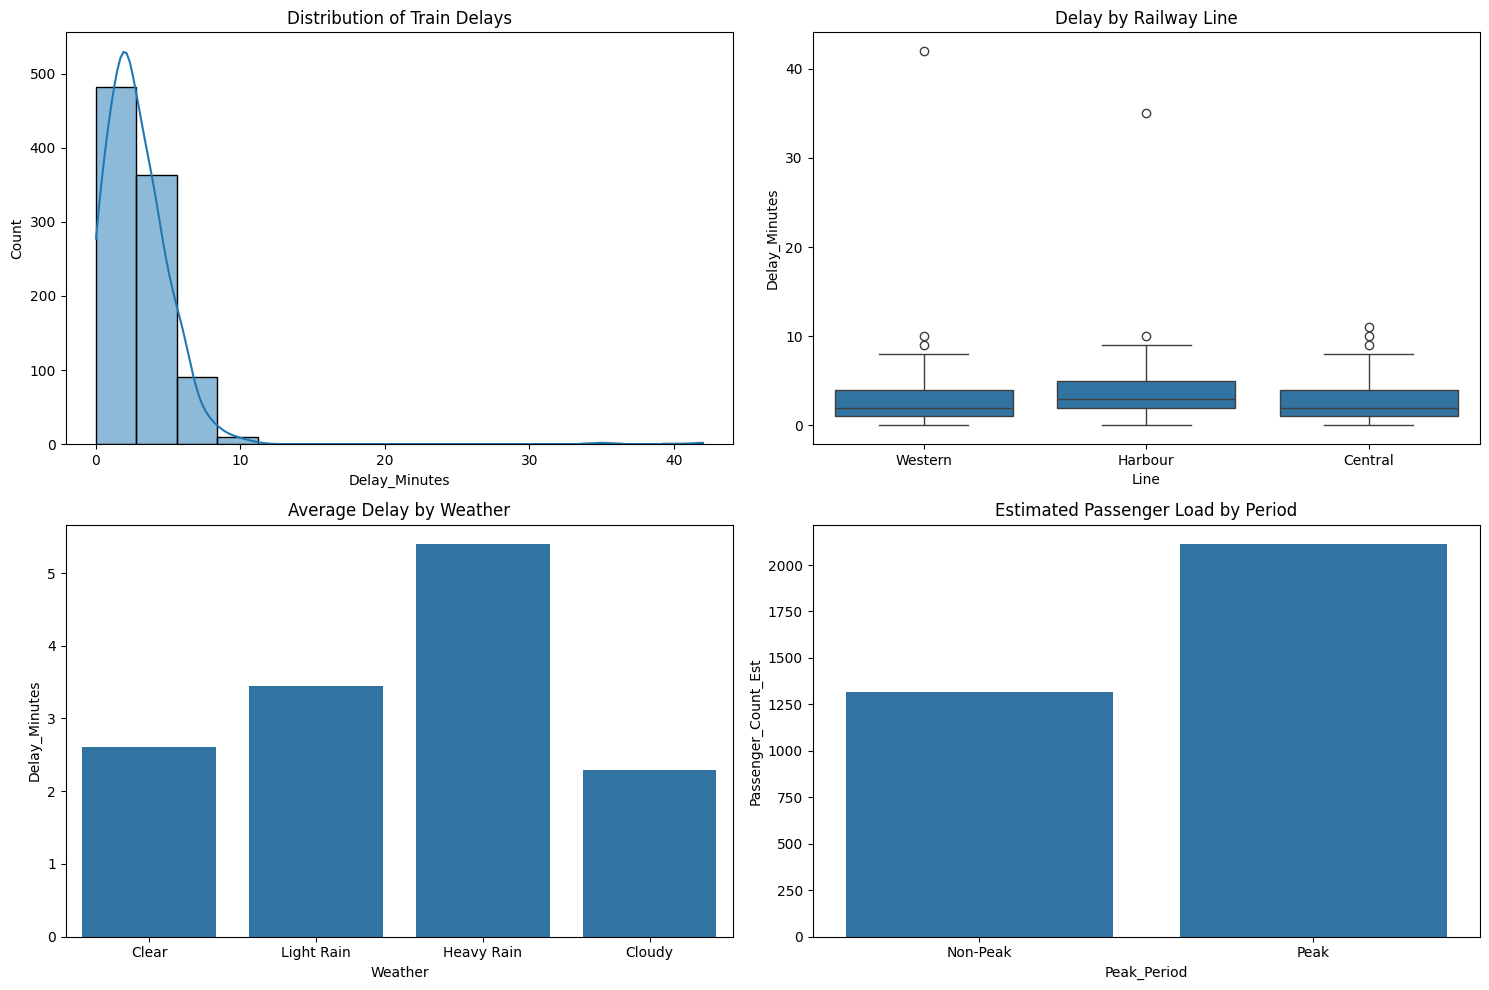

Average delay: 2.85
Maximum delay: 42.0
Estimated average passengers: 1787


,Journeys,Average_Delay,Average_Passengers
Line,,,
Central,330,2.71,1744.34
Harbour,182,3.71,1718.52
Western,434,2.61,1848.11


In [5]:
# Convert delay and passenger columns to numeric
df["Delay_Minutes"] = pd.to_numeric(df["Delay_Minutes"])
df["Passenger_Count_Est"] = pd.to_numeric(
    df["Passenger_Count_Est"]
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(
    data=df, x="Delay_Minutes", bins=15, kde=True, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Train Delays")

sns.boxplot(
    data=df, x="Line", y="Delay_Minutes", ax=axes[0, 1]
)
axes[0, 1].set_title("Delay by Railway Line")

sns.barplot(
    data=df, x="Weather", y="Delay_Minutes",
    errorbar=None, ax=axes[1, 0]
)
axes[1, 0].set_title("Average Delay by Weather")

sns.barplot(
    data=df, x="Peak_Period", y="Passenger_Count_Est",
    errorbar=None, ax=axes[1, 1]
)
axes[1, 1].set_title("Estimated Passenger Load by Period")

plt.tight_layout()
plt.show()

print("Average delay:", round(df["Delay_Minutes"].mean(), 2))
print("Maximum delay:", df["Delay_Minutes"].max())
print("Estimated average passengers:",
      round(df["Passenger_Count_Est"].mean()))

display(
    df.groupby("Line").agg(
        Journeys=("Journey_ID", "count"),
        Average_Delay=("Delay_Minutes", "mean"),
        Average_Passengers=("Passenger_Count_Est", "mean")
    ).round(2)
)

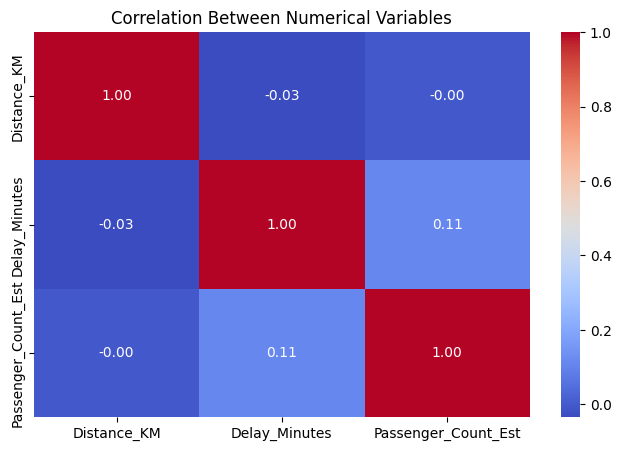

In [6]:
numeric_df = df[
    ["Distance_KM", "Delay_Minutes", "Passenger_Count_Est"]
]

plt.figure(figsize=(8, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Variables")
plt.show()

In [7]:
!pip -q install mlxtend

In [8]:
from mlxtend.frequent_patterns import apriori, association_rules

transactions = df[
    ["Line", "Train_Type", "Peak_Period", "Weather"]
].copy()

transactions["Delay_Group"] = np.where(
    df["Delay_Minutes"] >= 5,
    "High Delay",
    "Low Delay"
)

# Convert categories into transaction indicators
encoded = pd.get_dummies(transactions.astype(str))

frequent_itemsets = apriori(
    encoded,
    min_support=0.03,
    use_colnames=True
)

if len(frequent_itemsets) > 0:
    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.40
    )

    rules = rules.sort_values(
        ["lift", "confidence"], ascending=False
    )

    display(
        rules[
            ["antecedents", "consequents", "support",
             "confidence", "lift"]
        ].head(15)
    )
else:
    print("No frequent itemsets found. Reduce min_support.")

,antecedents,consequents,support,confidence,lift
52,(Weather_Heavy Rain),(Delay_Group_High Delay),0.036998,0.625000,3.303073
310,"(Peak_Period_Peak, Line_Harbour, Train_Type_Slow)",(Delay_Group_High Delay),0.033827,0.470588,2.487019
107,"(Peak_Period_Peak, Line_Harbour)",(Delay_Group_High Delay),0.044397,0.432990,2.288314
427,"(Weather_Cloudy, Peak_Period_Non-Peak)","(Delay_Group_Low Delay, Train_Type_Fast)",0.039112,0.468354,1.560082
531,"(Peak_Period_Peak, Delay_Group_Low Delay, Weat...","(Line_Western, Train_Type_Slow)",0.030655,0.453125,1.541929
526,"(Peak_Period_Peak, Train_Type_Slow, Delay_Grou...",(Line_Western),0.030655,0.690476,1.505047
490,"(Weather_Cloudy, Line_Central, Train_Type_Slow)","(Peak_Period_Peak, Delay_Group_Low Delay)",0.030655,0.674419,1.490654
415,"(Delay_Group_Low Delay, Weather_Light Rain, Pe...",(Line_Western),0.045455,0.671875,1.464502
451,"(Delay_Group_High Delay, Weather_Clear)","(Peak_Period_Peak, Train_Type_Slow)",0.039112,0.560606,1.445050
371,"(Delay_Group_High Delay, Line_Western)","(Peak_Period_Peak, Train_Type_Slow)",0.036998,0.555556,1.432031


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

K=2 | Silhouette Score: 0.293
K=3 | Silhouette Score: 0.283


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


K=4 | Silhouette Score: 0.292
K=5 | Silhouette Score: 0.271


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Distance_KM,Delay_Minutes,Passenger_Count_Est
Cluster,,,
0,28.57,2.00,1148.02
1,52.43,2.71,1853.97
2,25.94,3.64,2226.88


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

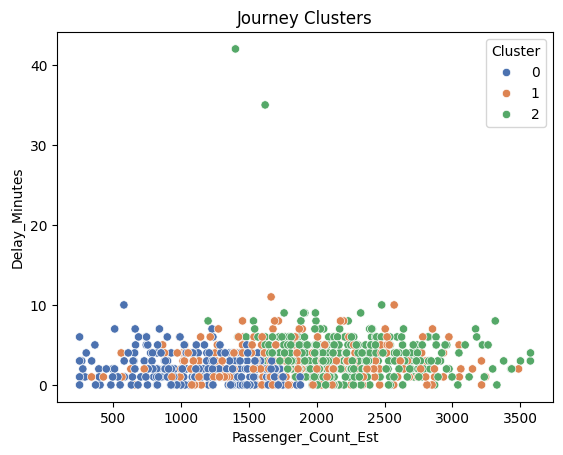

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    "Distance_KM",
    "Delay_Minutes",
    "Passenger_Count_Est"
]

X_cluster = df[cluster_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Test different cluster counts
for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    print(
        f"K={k} | Silhouette Score:",
        round(silhouette_score(X_scaled, labels), 3)
    )

# Use 3 clusters for an interpretable initial analysis
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

display(
    df.groupby("Cluster")[cluster_features].mean().round(2)
)

sns.scatterplot(
    data=df,
    x="Passenger_Count_Est",
    y="Delay_Minutes",
    hue="Cluster",
    palette="deep"
)
plt.title("Journey Clusters")
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Accuracy: 0.768

Classification Report:
              precision    recall  f1-score   support

   Low Delay       0.87      0.84      0.86       154
     Delayed       0.40      0.44      0.42        36

    accuracy                           0.77       190
   macro avg       0.63      0.64      0.64       190
weighted avg       0.78      0.77      0.77       190



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

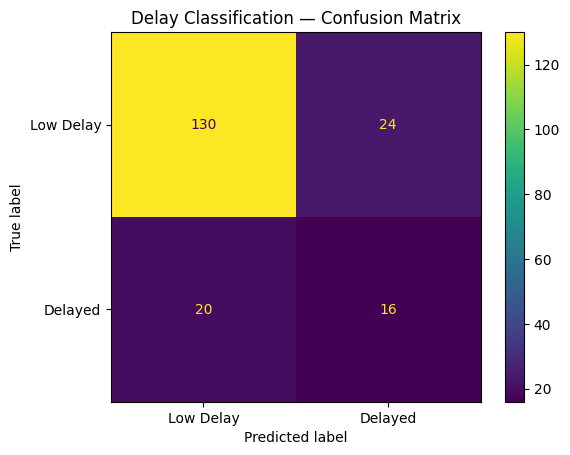

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model_df = df.copy()

# Target created from the delay threshold
y = (model_df["Delay_Minutes"] >= 5).astype(int)

# Features available for a hypothetical prediction
X = model_df[
    [
        "Line",
        "Train_Type",
        "Distance_KM",
        "Passenger_Count_Est",
        "Peak_Period",
        "Weather"
    ]
].copy()

categorical_features = [
    "Line", "Train_Type", "Peak_Period", "Weather"
]
numerical_features = [
    "Distance_KM", "Passenger_Count_Est"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("num", StandardScaler(), numerical_features)
    ]
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Low Delay", "Delayed"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Low Delay", "Delayed"]
)
plt.title("Delay Classification — Confusion Matrix")
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Feature,Importance
12,num__Passenger_Count_Est,0.272985
9,cat__Weather_Heavy Rain,0.263417
1,cat__Line_Harbour,0.215889
10,cat__Weather_Light Rain,0.125942
11,num__Distance_KM,0.078869
8,cat__Weather_Cloudy,0.023746
5,cat__Peak_Period_Non-Peak,0.017251
4,cat__Train_Type_Slow,0.001900
0,cat__Line_Central,0.000000
3,cat__Train_Type_Fast,0.000000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

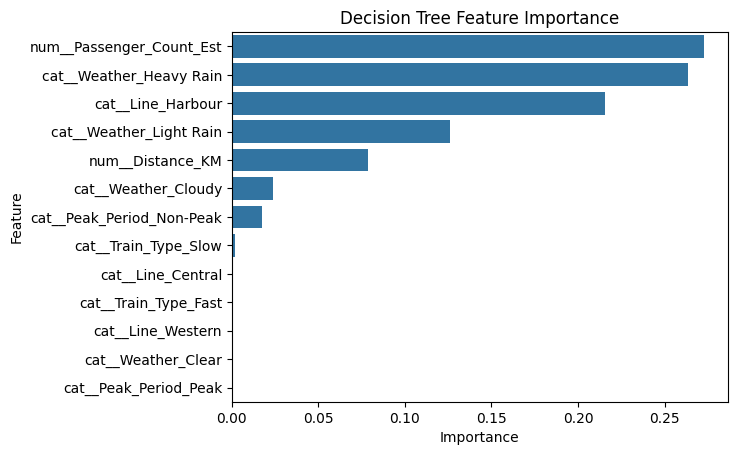

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
feature_names = (
    pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pipeline.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Decision Tree Feature Importance")
plt.show()

In [12]:
df["Predicted_Delay_Status"] = np.where(
    pipeline.predict(X) == 1,
    "Delayed",
    "Low Delay"
)

df.to_csv(
    "mumbai_local_mining_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Files exported successfully.")

files.download("mumbai_local_mining_results.csv")
files.download("feature_importance.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Files exported successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag